<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/30_expansion/32_expansion_arima.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 32 · ARIMA del % agropecuario y pronóstico a 2030

**Autor:** Daniel

**Pregunta (sección 11.2 de la ruta):** ¿a qué ritmo crece el uso agropecuario de la Altillanura y hacia dónde va en 2030?

**Entradas:**
- Tablas municipales de MapBiomas Colombia, Colección 3: `modulos/expansion/datos/mapbiomas_crudos/` (Git, datos crudos).

**Salidas** (en `modulos/expansion/resultados/` y `modulos/expansion/graficas/`):
- `32_arima_pruebas_estacionariedad.csv`, `32_arima_candidatos.csv`, `32_arima_prueba.csv`, `32_arima_validacion.csv`, `32_arima_pronostico_2030.csv`.
- `32_identificacion.png`, `32_validacion.png`, `32_diagnostico.png`, `32_pronostico_2030.png`.

**Modelos:**
1. Referencia (benchmark): caminata aleatoria con deriva. El crecimiento futuro es el crecimiento anual promedio del pasado.
2. ARIMA(p, d, q) sobre el % agropecuario anual de la región, con la especificación por defecto de statsmodels (sin constante cuando d ≥ 1).

**Estructura** (la misma para todos los modelos del informe, sección 14.2): datos, supuestos, selección, validación, predicción y límites.

## Paso 1. Rutas y librerías
- En **Colab** clona el repo en `/content/Proyecto-ALTILLANURA`.
- En **local** toma como raíz la carpeta del repo (dos niveles arriba del cuaderno).
- `traer(ruta)` baja de DVC un archivo cuando hace falta.

In [1]:
import os, sys, re, glob, subprocess, warnings
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
EXPANSION = os.path.join(RAIZ, 'modulos', 'expansion')
CRUDOS = os.path.join(EXPANSION, 'datos', 'mapbiomas_crudos')
RESULTADOS = os.path.join(EXPANSION, 'resultados')
GRAFICAS = os.path.join(EXPANSION, 'graficas')
os.makedirs(RESULTADOS, exist_ok=True)
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

def coma(valor, decimales=1):
    return f'{valor:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

ALFA = 0.05
FIN_ENTRENAMIENTO = 2018
ANIO_PRONOSTICO = 2030
MAXIMO_D = 2
MAXIMO_P = 3
MAXIMO_Q = 3
REZAGOS_LJUNG_BOX = [5, 10]
MODULO_MINIMO = 1.01

print('Raíz del repo:', RAIZ)

Raíz del repo: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto


## 1. Datos
El % agropecuario regional de cada año es el área de la "Zona agrícola y ganadera" (nivel 1 de MapBiomas) de los siete municipios sobre su área total. Es la misma definición de las series municipales y del cuaderno 30.

- **Entrenamiento:** 1985–2018 (34 años).
- **Prueba:** 2019–2024 (6 años), que el modelo no ve al ajustarse.

In [2]:
partes = []
for ruta in sorted(glob.glob(os.path.join(CRUDOS, '*.csv'))):
    mb = pd.read_csv(ruta, encoding='utf-8-sig')
    mb['Level 2'] = mb['Level 2'].fillna('').str.strip()
    mb = mb[mb['Level 2'] != '']
    largo = mb.melt(id_vars=['Level 1', 'Level 2'], var_name='anio', value_name='ha')
    largo['anio'] = largo['anio'].astype(int)
    largo['ha'] = pd.to_numeric(largo['ha'], errors='coerce').fillna(0.0)
    largo['mpio_cdpmp'] = re.search(r'(\d{5})_', os.path.basename(ruta)).group(1)
    partes.append(largo)
mb = pd.concat(partes, ignore_index=True)
assert mb['mpio_cdpmp'].nunique() == 7

region = mb.groupby('anio').agg(area_total_ha=('ha', 'sum'))
region['agro_ha'] = mb[mb['Level 1'] == 'Agricultural and livestock area'].groupby('anio')['ha'].sum()
region['agro_pct'] = region['agro_ha'] / region['area_total_ha'] * 100
serie = region['agro_pct']
ANIOS = serie.index.to_numpy()
AREA_TOTAL_HA = float(region['area_total_ha'].iloc[-1])

entrena = serie[serie.index <= FIN_ENTRENAMIENTO]
prueba = serie[serie.index > FIN_ENTRENAMIENTO]
H_PRUEBA = len(prueba)

print(f'Serie: {ANIOS.min()}–{ANIOS.max()} ({len(serie)} años) | entrenamiento: {len(entrena)} | prueba: {H_PRUEBA}')
print(f'% agropecuario: {ANIOS.min()}: {serie.iloc[0]:.2f} % | {FIN_ENTRENAMIENTO}: {entrena.iloc[-1]:.2f} % | {ANIOS.max()}: {serie.iloc[-1]:.2f} %')
print(f'Crecimiento anual promedio 1985–{FIN_ENTRENAMIENTO}: {np.diff(entrena).mean():.3f} puntos porcentuales')

Serie: 1985–2024 (40 años) | entrenamiento: 34 | prueba: 6
% agropecuario: 1985: 3.89 % | 2018: 11.03 % | 2024: 12.87 %
Crecimiento anual promedio 1985–2018: 0.216 puntos porcentuales


## 2. Supuestos: estacionariedad e identificación
ARIMA necesita una serie estacionaria después de diferenciarla *d* veces. Se prueban d = 0, 1 y 2 sobre el entrenamiento con dos pruebas que se complementan:
- **ADF**: la hipótesis nula es que hay raíz unitaria (no estacionaria). Se rechaza con p < 0,05.
- **KPSS**: la hipótesis nula es que la serie es estacionaria. No se rechaza con p > 0,05.

Se toma la menor *d* en que las dos coinciden. Si no coinciden, se toma la mayor, salvo que muestre señales de sobrediferenciación (autocorrelación de rezago 1 menor que −0,5 o más varianza que con la *d* menor).

La figura muestra la serie original, la serie diferenciada y la ACF y PACF de la serie diferenciada, que orientan los órdenes *p* y *q*.

 d  adf_p  kpss_p  acf_rezago_1  desviacion
 0 0.9989  0.0100        0.8887      1.9494
 1 0.3930  0.0971        0.2990      0.1281
 2 0.0000  0.1000       -0.4575      0.1412

d elegida: 1 (ADF y KPSS no coinciden; con d = 2 hay señales de sobrediferenciación)


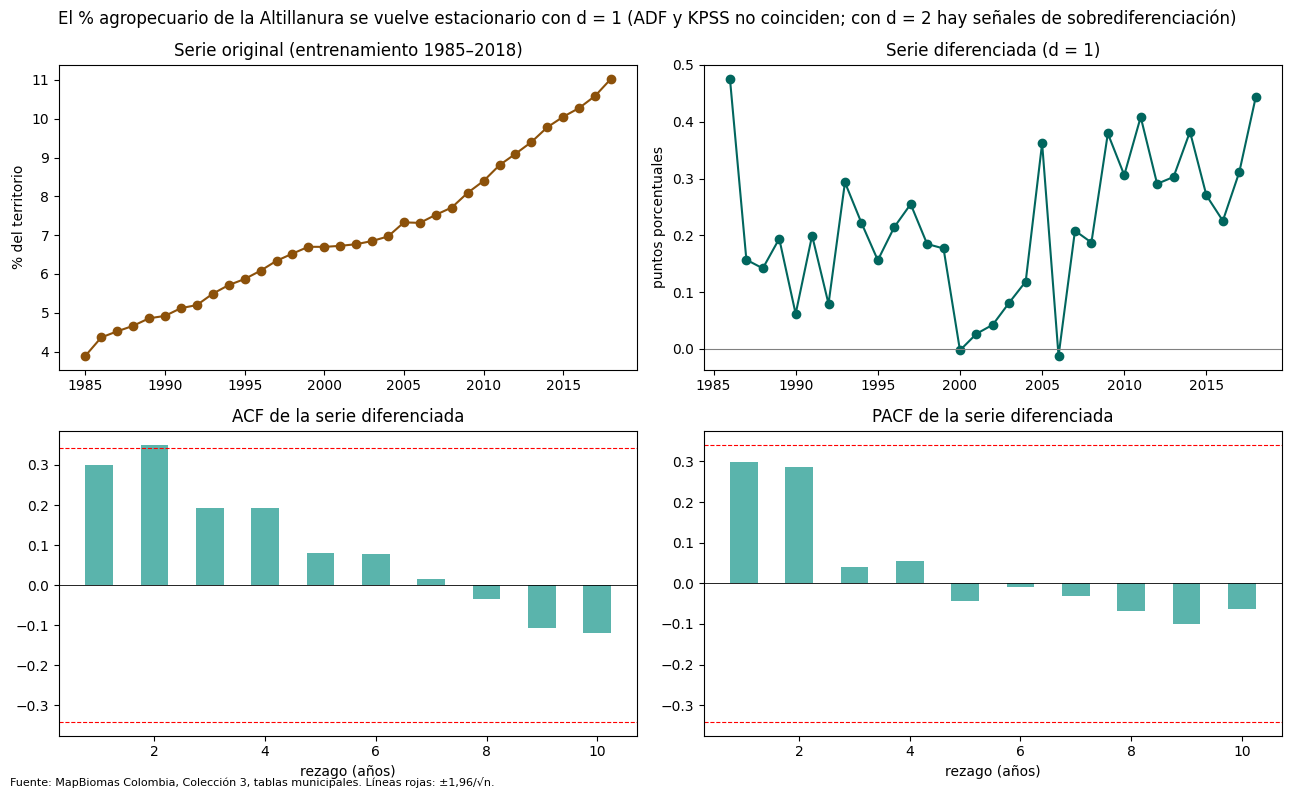

In [3]:
def sin_avisos(funcion, *args, **kwargs):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return funcion(*args, **kwargs)

y_e = entrena.to_numpy()
filas = []
for d in range(MAXIMO_D + 1):
    x = np.diff(y_e, n=d)
    adf = sin_avisos(adfuller, x, regression='c', autolag='AIC')
    prueba_kpss = sin_avisos(kpss, x, regression='c', nlags='auto')
    filas.append({'d': d, 'adf_p': adf[1], 'kpss_p': prueba_kpss[1],
                  'acf_rezago_1': acf(x, nlags=1, fft=False)[1], 'desviacion': x.std(ddof=1)})
pruebas = pd.DataFrame(filas)

adf_ok = pruebas.loc[pruebas['adf_p'] < ALFA, 'd']
kpss_ok = pruebas.loc[pruebas['kpss_p'] > ALFA, 'd']
if adf_ok.empty and kpss_ok.empty:
    D = int(pruebas.loc[pruebas['desviacion'].idxmin(), 'd'])
    razon_d = 'ninguna prueba indica estacionariedad; se usa la d de menor desviación'
elif adf_ok.empty or kpss_ok.empty:
    D = int((kpss_ok if adf_ok.empty else adf_ok).min())
    razon_d = f'solo {"KPSS" if adf_ok.empty else "ADF"} indica estacionariedad'
elif adf_ok.min() == kpss_ok.min():
    D = int(adf_ok.min())
    razon_d = 'ADF y KPSS coinciden'
else:
    menor, mayor = sorted((int(adf_ok.min()), int(kpss_ok.min())))
    t = pruebas.set_index('d')
    sobre = t.loc[mayor, 'acf_rezago_1'] < -0.5 or t.loc[mayor, 'desviacion'] > t.loc[menor, 'desviacion']
    D = menor if sobre else mayor
    razon_d = f'ADF y KPSS no coinciden; con d = {mayor} {"hay" if sobre else "no hay"} señales de sobrediferenciación'

pruebas.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_pruebas_estacionariedad.csv'), index=False)
print(pruebas.round(4).to_string(index=False))
print(f'\nd elegida: {D} ({razon_d})')

dif = np.diff(y_e, n=D)
rezagos = min(10, len(dif) // 2 - 1)
banda = 1.96 / np.sqrt(len(dif))
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(entrena.index, y_e, marker='o', color='#8c510a')
axes[0, 0].set_title('Serie original (entrenamiento 1985–2018)')
axes[0, 0].set_ylabel('% del territorio')
axes[0, 1].plot(entrena.index[D:], dif, marker='o', color='#01665e')
axes[0, 1].axhline(0, color='grey', linewidth=0.8)
axes[0, 1].set_title(f'Serie diferenciada (d = {D})')
axes[0, 1].set_ylabel('puntos porcentuales' if D == 1 else f'diferencia de orden {D}')
for ax, valores, nombre in ((axes[1, 0], acf(dif, nlags=rezagos, fft=False), 'ACF'),
                             (axes[1, 1], pacf(dif, nlags=rezagos, method='ywm'), 'PACF')):
    ax.bar(range(1, rezagos + 1), valores[1:rezagos + 1], color='#5ab4ac', width=0.5)
    ax.axhline(banda, color='red', linestyle='--', linewidth=0.8)
    ax.axhline(-banda, color='red', linestyle='--', linewidth=0.8)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_title(f'{nombre} de la serie diferenciada')
    ax.set_xlabel('rezago (años)')
fig.suptitle(f'El % agropecuario de la Altillanura se vuelve estacionario con d = {D} ({razon_d})', fontsize=12)
fig.text(0.01, 0.01, 'Fuente: MapBiomas Colombia, Colección 3, tablas municipales. Líneas rojas: ±1,96/√n.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '32_identificacion.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Selección del modelo
Se ajustan todos los ARIMA(p, D, q) con p y q entre 0 y 3 sobre el entrenamiento y se ordenan por **AICc**. Para que un modelo sea apto debe cumplir:
- que el ajuste converja;
- raíces AR y MA fuera del círculo unitario (módulo > 1,01: estacionario e invertible);
- coeficientes significativos (p < 0,05);
- residuos sin autocorrelación (Ljung-Box en los rezagos 5 y 10, p > 0,05).

Se elige el de menor AICc entre los aptos; si ninguno es apto, el de menor AICc.

In [4]:
def ajustar(y, orden):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return ARIMA(np.asarray(y, dtype=float), order=orden).fit()

def modulos_raices(res):
    nombres = list(res.model.param_names)
    params = np.asarray(res.params, dtype=float)
    ar = [v for n, v in zip(nombres, params) if n.startswith('ar.')]
    ma = [v for n, v in zip(nombres, params) if n.startswith('ma.')]
    modulos = [abs(r) for r in np.roots(np.r_[-np.array(ar)[::-1], 1.0])] if ar else []
    modulos += [abs(r) for r in np.roots(np.r_[np.array(ma)[::-1], 1.0])] if ma else []
    return modulos

def raices_ok(res):
    return all(m > MODULO_MINIMO for m in modulos_raices(res))

def ljung_box(res, d, k):
    residuos = np.asarray(res.resid)[d:]
    tabla = acorr_ljungbox(residuos, lags=REZAGOS_LJUNG_BOX, model_df=k)
    return float(np.min(tabla['lb_pvalue'].to_numpy()))

filas, ajustes = [], {}
for p in range(MAXIMO_P + 1):
    for q in range(MAXIMO_Q + 1):
        try:
            res = ajustar(y_e, (p, D, q))
        except Exception as error:
            print(f'ARIMA({p},{D},{q}) no se pudo ajustar: {error}')
            continue
        nombres = list(res.model.param_names)
        p_valores = np.asarray(res.pvalues, dtype=float)
        sin_sigma = [pv for n, pv in zip(nombres, p_valores) if n != 'sigma2']
        lb_p = ljung_box(res, D, p + q)
        ajustes[(p, q)] = res
        filas.append({'modelo': f'ARIMA({p},{D},{q})', 'p': p, 'd': D, 'q': q, 'aicc': res.aicc,
                      'converge': bool((getattr(res, 'mle_retvals', None) or {}).get('converged', True)),
                      'raices_ok': raices_ok(res),
                      'coef_significativos': bool(all(pv < ALFA for pv in sin_sigma)) if sin_sigma else True,
                      'ljung_box_p': lb_p, 'ljung_box_ok': lb_p > ALFA})
candidatos = pd.DataFrame(filas).sort_values('aicc').reset_index(drop=True)
candidatos['apto'] = candidatos[['converge', 'raices_ok', 'coef_significativos', 'ljung_box_ok']].all(axis=1)
aptos = candidatos[candidatos['apto']]
elegido = aptos.iloc[0] if not aptos.empty else candidatos.iloc[0]
ORDEN = (int(elegido['p']), D, int(elegido['q']))
NOMBRE = elegido['modelo']
razon_modelo = 'el de menor AICc entre los aptos' if not aptos.empty else 'ningún modelo es apto; se deja el de menor AICc'

candidatos.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_candidatos.csv'), index=False)
print(candidatos.head(10).round(3).to_string(index=False))
print(f'\nModelo elegido: {NOMBRE} ({razon_modelo})')

      modelo  p  d  q    aicc  converge  raices_ok  coef_significativos  ljung_box_p  ljung_box_ok  apto
ARIMA(1,1,1)  1  1  1 -37.750      True       True                 True        0.764          True  True
ARIMA(2,1,0)  2  1  0 -37.643      True       True                 True        0.489          True  True
ARIMA(2,1,1)  2  1  1 -35.535      True       True                False        0.557          True False
ARIMA(1,1,2)  1  1  2 -35.323      True       True                False        0.580          True False
ARIMA(3,1,0)  3  1  0 -35.297      True       True                False        0.423          True False
ARIMA(3,1,1)  3  1  1 -33.790     False      False                False        0.278          True False
ARIMA(1,1,3)  1  1  3 -33.367      True      False                False        0.355          True False
ARIMA(2,1,2)  2  1  2 -33.094      True       True                False        0.278          True False
ARIMA(1,1,0)  1  1  0 -31.742      True       True     

## 4. Validación con 2019–2024
Con los datos hasta 2018 se pronostican 2019–2024 (1 a 6 años adelante) con el ARIMA elegido y con la caminata con deriva, y se comparan con lo observado.

- **MAE** y **RMSE**: error medio absoluto y raíz del error cuadrático medio, en puntos porcentuales.
- **MAPE**: error porcentual absoluto medio, en % del valor observado.
- **MASE**: MAE dividido entre el error medio de la caminata ingenua (sin deriva) de un paso en el entrenamiento. Menos de 1 es mejor que esa referencia.
- **MAE relativo a la caminata con deriva**: MAE del ARIMA sobre MAE de la caminata con deriva. Menos de 1 significa que el ARIMA le gana a la referencia.
- **Cobertura**: % de años de prueba dentro del intervalo del 95 %.

             modelo  mae_pp  rmse_pp  mape_pct  mase  cobertura_95_pct  mae_relativo_caminata
       ARIMA(1,1,1)   0.172    0.184     1.453 0.791             100.0                  0.661
Caminata con deriva   0.260    0.323     2.095 1.198             100.0                  1.000

Mejor en la prueba 2019–2024: ARIMA(1,1,1)


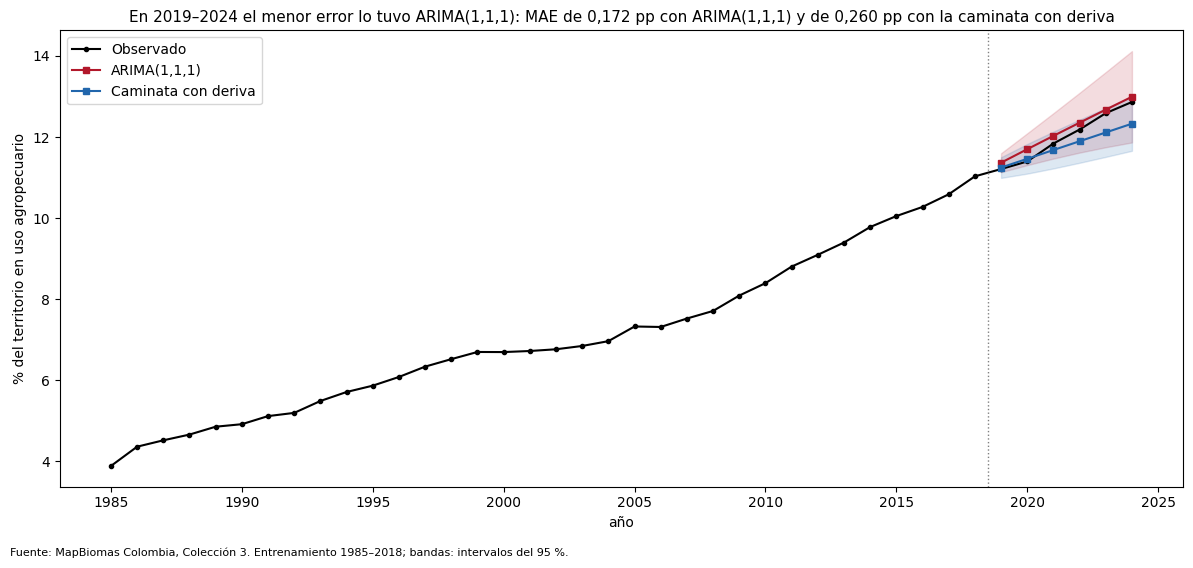

In [5]:
def caminata_con_deriva(y, pasos):
    y = np.asarray(y, dtype=float)
    cambios = np.diff(y)
    deriva = cambios.mean()
    sigma = np.sqrt(np.sum((cambios - deriva) ** 2) / (len(cambios) - 1))
    h = np.arange(1, pasos + 1)
    media = y[-1] + h * deriva
    se = sigma * np.sqrt(h * (1 + h / len(cambios)))
    z = stats.norm.ppf(1 - ALFA / 2)
    return pd.DataFrame({'mean': media, 'mean_ci_lower': media - z * se, 'mean_ci_upper': media + z * se})

def pronostico_arima(res, pasos):
    marco = res.get_forecast(steps=pasos).summary_frame(alpha=ALFA)
    return pd.DataFrame({c: np.asarray(marco[c], dtype=float) for c in ('mean', 'mean_ci_lower', 'mean_ci_upper')})

res_entrena = ajustes[(ORDEN[0], ORDEN[2])]
escala_mase = np.mean(np.abs(np.diff(y_e)))
observado = prueba.to_numpy()

tablas, metricas = [], []
for nombre, marco in ((NOMBRE, pronostico_arima(res_entrena, H_PRUEBA)), ('Caminata con deriva', caminata_con_deriva(y_e, H_PRUEBA))):
    error = marco['mean'].to_numpy() - observado
    dentro = (observado >= marco['mean_ci_lower']) & (observado <= marco['mean_ci_upper'])
    tablas.append(pd.DataFrame({'modelo': nombre, 'anio': prueba.index, 'horizonte': np.arange(1, H_PRUEBA + 1),
                                'observado_pct': observado, 'pronostico_pct': marco['mean'],
                                'inferior_95': marco['mean_ci_lower'], 'superior_95': marco['mean_ci_upper'], 'error_pp': error}))
    metricas.append({'modelo': nombre, 'mae_pp': np.mean(np.abs(error)), 'rmse_pp': np.sqrt(np.mean(error ** 2)),
                     'mape_pct': np.mean(np.abs(error) / np.abs(observado)) * 100,
                     'mase': np.mean(np.abs(error)) / escala_mase, 'cobertura_95_pct': dentro.mean() * 100})
detalle = pd.concat(tablas, ignore_index=True)
metricas = pd.DataFrame(metricas)
metricas['mae_relativo_caminata'] = metricas['mae_pp'] / metricas.loc[metricas['modelo'] == 'Caminata con deriva', 'mae_pp'].iloc[0]

detalle.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_prueba.csv'), index=False)
metricas.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_validacion.csv'), index=False)
print(metricas.round(3).to_string(index=False))
GANA = metricas.loc[metricas['mae_pp'].idxmin(), 'modelo']
print(f'\nMejor en la prueba 2019–2024: {GANA}')

colores = {NOMBRE: '#b2182b', 'Caminata con deriva': '#2166ac'}
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(serie.index, serie.values, color='black', marker='o', markersize=3, label='Observado')
ax.axvline(FIN_ENTRENAMIENTO + 0.5, color='grey', linestyle=':', linewidth=1)
for nombre, grupo in detalle.groupby('modelo', sort=False):
    ax.plot(grupo['anio'], grupo['pronostico_pct'], color=colores[nombre], marker='s', markersize=4, label=nombre)
    ax.fill_between(grupo['anio'], grupo['inferior_95'], grupo['superior_95'], color=colores[nombre], alpha=0.15)
ax.set_ylabel('% del territorio en uso agropecuario')
ax.set_xlabel('año')
ax.legend()
fila_a = metricas[metricas['modelo'] == NOMBRE].iloc[0]
fila_c = metricas[metricas['modelo'] == 'Caminata con deriva'].iloc[0]
ax.set_title(f'En 2019–2024 el menor error lo tuvo {GANA}: MAE de {coma(fila_a.mae_pp, 3)} pp con {NOMBRE} '
             f'y de {coma(fila_c.mae_pp, 3)} pp con la caminata con deriva', fontsize=11)
fig.text(0.01, -0.02, 'Fuente: MapBiomas Colombia, Colección 3. Entrenamiento 1985–2018; bandas: intervalos del 95 %.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '32_validacion.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Predicción a 2030
El modelo elegido se vuelve a ajustar con toda la serie (1985–2024) y se revisan sus residuos:
- **Ljung-Box** (rezagos 5 y 10): sin autocorrelación si p > 0,05.
- **Shapiro-Wilk** y **Jarque-Bera**: normalidad si p > 0,05. Si falla, los intervalos del 95 % son aproximados.
- **Coeficientes** y módulo mínimo de las raíces AR y MA: un módulo cerca de 1 indica que el ritmo de crecimiento es muy persistente (ver Límites).

Luego se pronostica 2025–2030 con su intervalo del 95 %, junto con la caminata con deriva. El pronóstico se da en % del territorio y en hectáreas (con el área total de 2024).

ARIMA(1,1,1) con 1985–2024: ljung_box_p_5 = 0.876 | ljung_box_p_10 = 0.987 | shapiro_p = 0.193 | jarque_bera_p = 0.022
Coeficientes: ar.L1 = 0.992 | ma.L1 = -0.703 | sigma2 = 0.014 | módulo mínimo de las raíces = 1.008


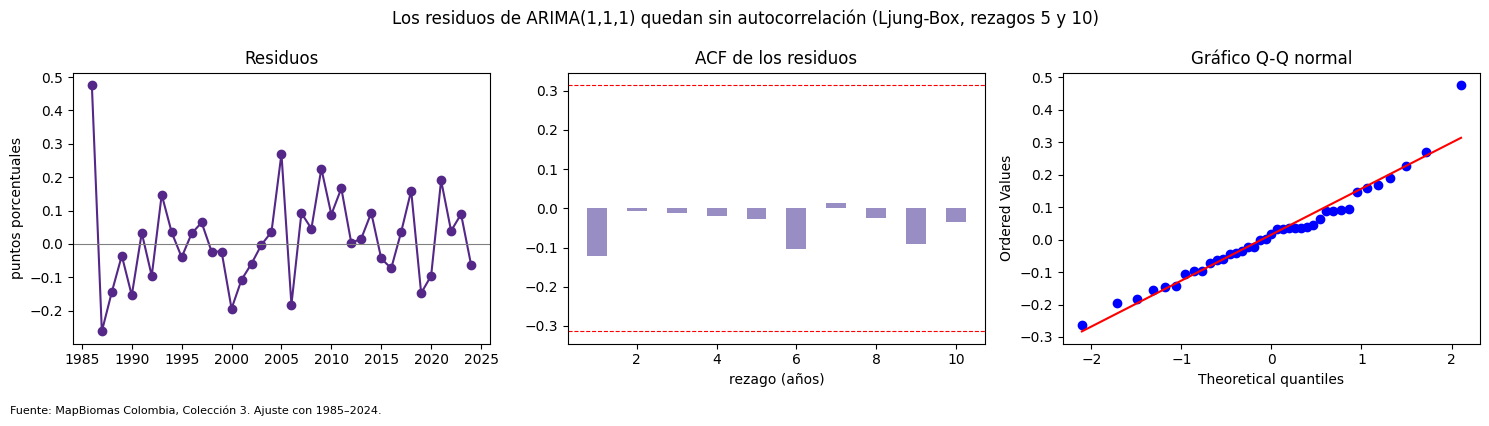

             modelo  anio  agro_pct  inferior_95_pct  superior_95_pct    agro_ha  inferior_95_ha  superior_95_ha
       ARIMA(1,1,1)  2030     14.73            13.72            15.75 1986888.10      1849988.01      2123788.19
Caminata con deriva  2030     14.25            13.58            14.91 1921509.39      1832211.09      2010807.68


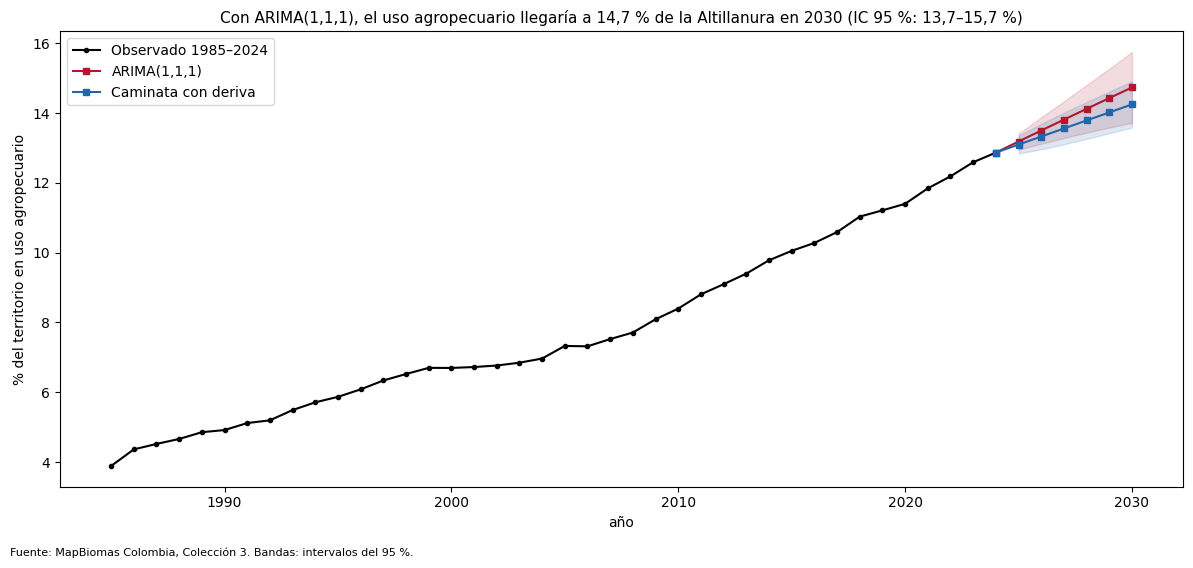

In [6]:
y_total = serie.to_numpy()
res_final = ajustar(y_total, ORDEN)
residuos = np.asarray(res_final.resid)[ORDEN[1]:]
lb = acorr_ljungbox(residuos, lags=REZAGOS_LJUNG_BOX, model_df=ORDEN[0] + ORDEN[2])
diagnostico = {f'ljung_box_p_{r}': float(v) for r, v in zip(REZAGOS_LJUNG_BOX, lb['lb_pvalue'].to_numpy())}
diagnostico['shapiro_p'] = float(stats.shapiro(residuos)[1])
diagnostico['jarque_bera_p'] = float(jarque_bera(residuos)[1])
print(f'{NOMBRE} con 1985–2024:', ' | '.join(f'{k} = {v:.3f}' for k, v in diagnostico.items()))
COEFICIENTES = dict(zip(res_final.model.param_names, np.asarray(res_final.params, dtype=float)))
MODULO_FINAL = min(modulos_raices(res_final), default=np.nan)
print('Coeficientes:', ' | '.join(f'{k} = {v:.3f}' for k, v in COEFICIENTES.items()), f'| módulo mínimo de las raíces = {MODULO_FINAL:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(serie.index[ORDEN[1]:], residuos, marker='o', color='#542788')
axes[0].axhline(0, color='grey', linewidth=0.8)
axes[0].set_title('Residuos')
axes[0].set_ylabel('puntos porcentuales')
rez = min(10, len(residuos) // 2 - 1)
axes[1].bar(range(1, rez + 1), acf(residuos, nlags=rez, fft=False)[1:], color='#998ec3', width=0.5)
for signo in (1, -1):
    axes[1].axhline(signo * 1.96 / np.sqrt(len(residuos)), color='red', linestyle='--', linewidth=0.8)
axes[1].set_title('ACF de los residuos')
axes[1].set_xlabel('rezago (años)')
stats.probplot(residuos, dist='norm', plot=axes[2])
axes[2].set_title('Gráfico Q-Q normal')
estado = 'sin autocorrelación' if min(diagnostico['ljung_box_p_5'], diagnostico['ljung_box_p_10']) > ALFA else 'con autocorrelación'
fig.suptitle(f'Los residuos de {NOMBRE} quedan {estado} (Ljung-Box, rezagos 5 y 10)', fontsize=12)
fig.text(0.01, -0.03, 'Fuente: MapBiomas Colombia, Colección 3. Ajuste con 1985–2024.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '32_diagnostico.png'), dpi=150, bbox_inches='tight')
plt.show()

pasos = ANIO_PRONOSTICO - int(ANIOS.max())
futuro = np.arange(ANIOS.max() + 1, ANIO_PRONOSTICO + 1)
partes = []
for nombre, marco in ((NOMBRE, pronostico_arima(res_final, pasos)), ('Caminata con deriva', caminata_con_deriva(y_total, pasos))):
    tabla = pd.DataFrame({'modelo': nombre, 'anio': futuro, 'agro_pct': marco['mean'],
                          'inferior_95_pct': marco['mean_ci_lower'], 'superior_95_pct': marco['mean_ci_upper']})
    for c in ('agro_pct', 'inferior_95_pct', 'superior_95_pct'):
        tabla[c.replace('_pct', '_ha')] = tabla[c] / 100 * AREA_TOTAL_HA
    partes.append(tabla)
pronostico = pd.concat(partes, ignore_index=True)
pronostico.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_pronostico_2030.csv'), index=False)
print(pronostico[pronostico['anio'] == ANIO_PRONOSTICO].round(2).to_string(index=False))

final = pronostico[(pronostico['modelo'] == NOMBRE) & (pronostico['anio'] == ANIO_PRONOSTICO)].iloc[0]
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(serie.index, serie.values, color='black', marker='o', markersize=3, label='Observado 1985–2024')
for nombre, grupo in pronostico.groupby('modelo', sort=False):
    ax.plot(np.r_[ANIOS.max(), grupo['anio']], np.r_[y_total[-1], grupo['agro_pct']], color=colores[nombre], marker='s', markersize=4, label=nombre)
    ax.fill_between(grupo['anio'], grupo['inferior_95_pct'], grupo['superior_95_pct'], color=colores[nombre], alpha=0.15)
ax.set_ylabel('% del territorio en uso agropecuario')
ax.set_xlabel('año')
ax.legend(loc='upper left')
ax.set_title(f'Con {NOMBRE}, el uso agropecuario llegaría a {coma(final.agro_pct)} % de la Altillanura en {ANIO_PRONOSTICO} '
             f'(IC 95 %: {coma(final.inferior_95_pct)}–{coma(final.superior_95_pct)} %)', fontsize=11)
fig.text(0.01, -0.02, 'Fuente: MapBiomas Colombia, Colección 3. Bandas: intervalos del 95 %.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '32_pronostico_2030.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6. Límites
- La serie es corta: 34 años de entrenamiento y una sola ventana de prueba de 6 años, así que las métricas de validación tienen mucha incertidumbre.
- ARIMA solo extrapola la dinámica pasada de la serie. No incluye causas como precios, crédito, vías, políticas o tenencia de la tierra, y no anticipa cambios de régimen.
- El nivel 1 "Zona agrícola y ganadera" incluye el mosaico de agricultura y pastos, así que mezcla cultivos con ganadería.
- Los intervalos del 95 % suponen residuos normales; si Shapiro-Wilk o Jarque-Bera rechazan normalidad, son aproximados.
- Si en el ajuste final el módulo de una raíz AR queda cerca de 1, el ritmo de crecimiento anual es muy persistente: el ARIMA proyecta el ritmo de los últimos años y la caminata con deriva el promedio de toda la serie. La distancia entre los dos pronósticos de 2030 muestra cuánto pesa esa diferencia.
- Una nueva colección de MapBiomas puede reclasificar años anteriores y mover la serie.

## Resumen para el informe

In [7]:
a = metricas.set_index('modelo')
print(f'Datos: % agropecuario anual de la Altillanura (MapBiomas Col. 3), {ANIOS.min()}–{ANIOS.max()}; '
      f'pasó de {coma(serie.iloc[0], 2)} % a {coma(serie.iloc[-1], 2)} %.')
print(f'Supuestos: d = {D} ({razon_d}).')
print(f'Selección: {NOMBRE}, {razon_modelo} entre {len(candidatos)} candidatos.')
print(f'Validación 2019–2024: MAE {coma(a.loc[NOMBRE, "mae_pp"], 3)} pp, MAPE {coma(a.loc[NOMBRE, "mape_pct"], 2)} %, '
      f'MASE {coma(a.loc[NOMBRE, "mase"], 2)}; caminata con deriva: MAE {coma(a.loc["Caminata con deriva", "mae_pp"], 3)} pp, '
      f'MASE {coma(a.loc["Caminata con deriva", "mase"], 2)}. MAE relativo del ARIMA: {coma(a.loc[NOMBRE, "mae_relativo_caminata"], 2)}.')
print(f'Predicción {ANIO_PRONOSTICO}: {coma(final.agro_pct, 2)} % (IC 95 %: {coma(final.inferior_95_pct, 2)}–{coma(final.superior_95_pct, 2)} %), '
      f'unas {coma(final.agro_ha / 1e3, 0)} mil ha.')
ritmo_arima = (final.agro_pct - serie.iloc[-1]) / pasos
ritmo_reciente = (serie.iloc[-1] - serie.loc[FIN_ENTRENAMIENTO]) / H_PRUEBA
print(f'Ritmo: {NOMBRE} sube {coma(ritmo_arima, 2)} pp por año hasta {ANIO_PRONOSTICO} (módulo mínimo de las raíces: {coma(MODULO_FINAL, 3)}); '
      f'la caminata con deriva, {coma(np.diff(y_total).mean(), 2)} pp por año (promedio {ANIOS.min()}–{ANIOS.max()}); '
      f'en {FIN_ENTRENAMIENTO}–{ANIOS.max()} la serie subió {coma(ritmo_reciente, 2)} pp por año.')

Datos: % agropecuario anual de la Altillanura (MapBiomas Col. 3), 1985–2024; pasó de 3,89 % a 12,87 %.
Supuestos: d = 1 (ADF y KPSS no coinciden; con d = 2 hay señales de sobrediferenciación).
Selección: ARIMA(1,1,1), el de menor AICc entre los aptos entre 16 candidatos.
Validación 2019–2024: MAE 0,172 pp, MAPE 1,45 %, MASE 0,79; caminata con deriva: MAE 0,260 pp, MASE 1,20. MAE relativo del ARIMA: 0,66.
Predicción 2030: 14,73 % (IC 95 %: 13,72–15,75 %), unas 1.987 mil ha.
Ritmo: ARIMA(1,1,1) sube 0,31 pp por año hasta 2030 (módulo mínimo de las raíces: 1,008); la caminata con deriva, 0,23 pp por año (promedio 1985–2024); en 2018–2024 la serie subió 0,31 pp por año.
